 Essai Condition  Duree (s)  Vitesse (km/h)  ENMO 1 (mg)  ENMO 2 (mg)  Ecart-type 1 (mg)  Ecart-type 2 (mg)  Cadence 1 (pas/min)  Cadence 2 (pas/min)  Correlation  PLV
     1        C1      111.0            4.54       170.65       124.62             187.05             158.05                109.8                109.8         1.00 0.99
     2        C1      110.0            4.58       250.57       199.59             289.08             251.73                111.0                111.0         1.00 1.00
     3        C1      114.0            4.42       261.21       213.36             314.97             275.30                109.8                109.8         1.00 1.00
     4        C2      122.0            4.13       247.48       216.04             294.21             253.25                109.8                109.8         0.23 0.28
     5        C2      123.0            4.10       159.28       110.20             178.74             148.57                108.6                106.5         0.

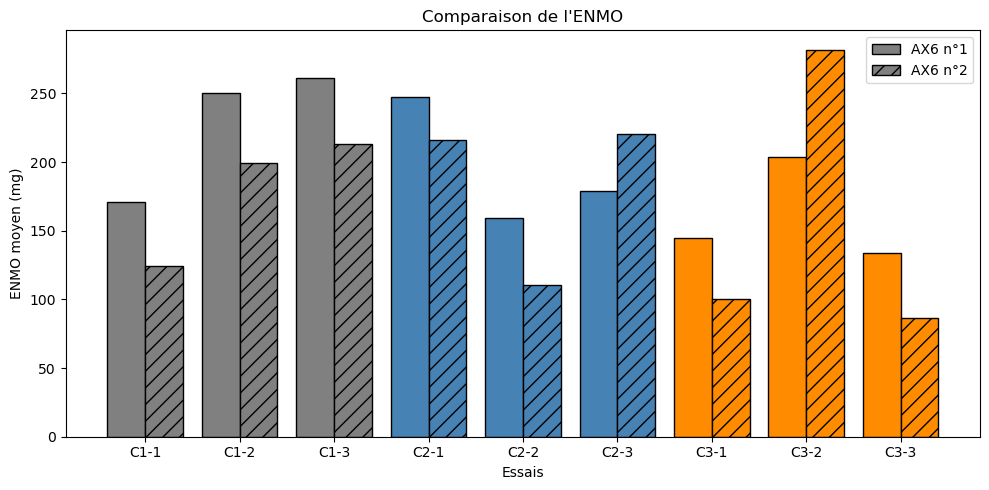

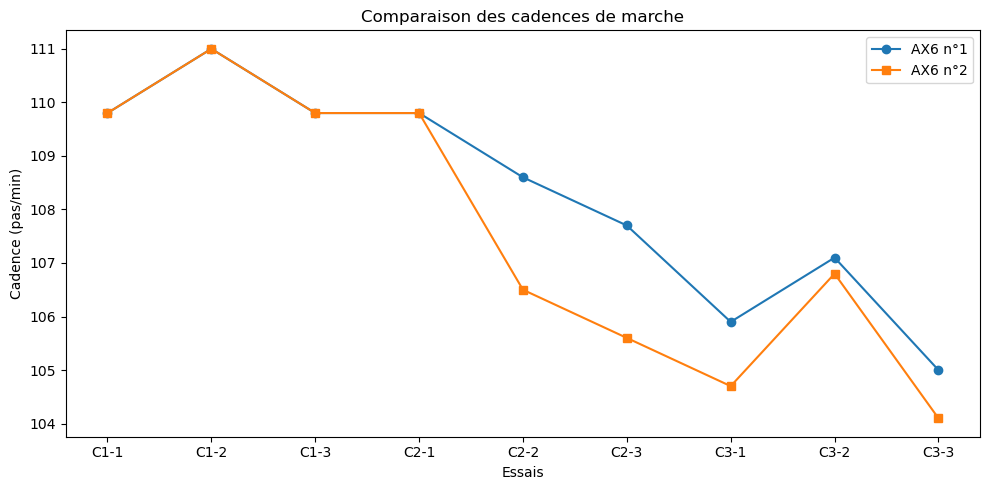

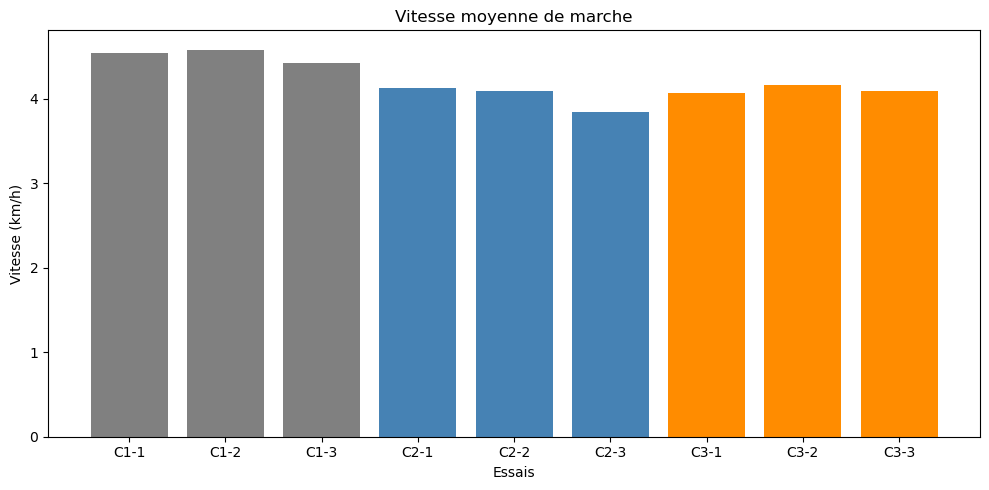

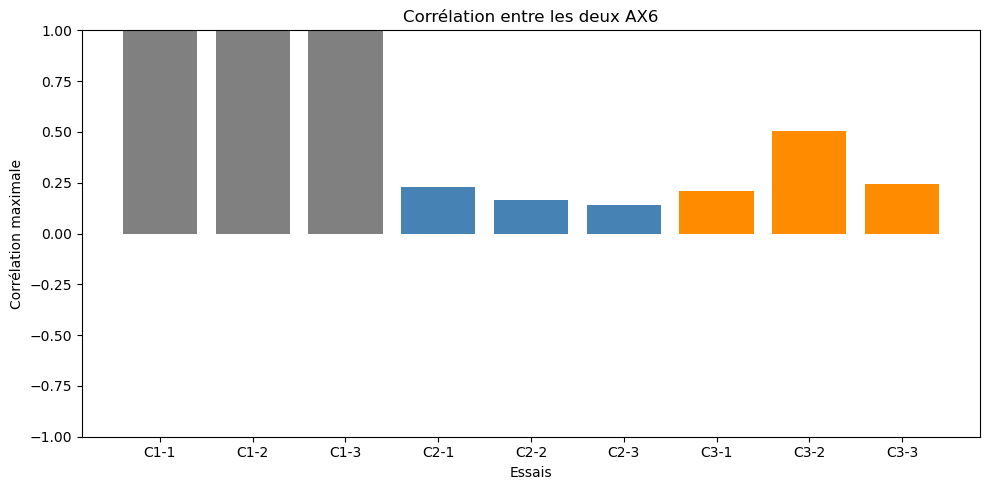

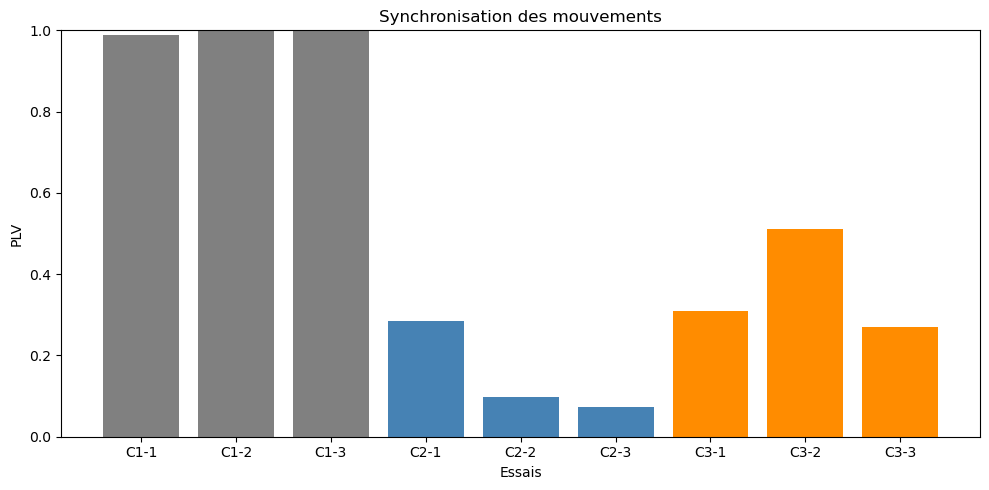

In [1]:
# -------------------- IMPORTATION DES BIBLIOTHÈQUES --------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path


# -------------------- IMPORTATION DES FICHIERS --------------------

dossier = Path("data")

df1 = pd.read_csv(dossier / "TEST1_AX6.csv", sep=";", header=None,
                  usecols=[0, 1, 2, 3], names=["Temps", "X", "Y", "Z"])

df2 = pd.read_csv(dossier / "TEST2_AX6.csv", sep=";", header=None,
                  usecols=[0, 1, 2, 3], names=["Temps", "X", "Y", "Z"])


# -------------------- CALCUL DE LA NORME ET DE L'ENMO --------------------

for df in [df1, df2]:

    df["Temps"] = pd.to_datetime(df["Temps"])
    df.sort_values("Temps", inplace=True)

    df["Norme"] = np.sqrt(df["X"]**2 + df["Y"]**2 + df["Z"]**2)
    df["ENMO"] = np.maximum(df["Norme"] - 1, 0) * 1000


# -------------------- PLAGES HORAIRES --------------------

plages = [
    ("17:17:36", "17:19:27", "C1"),
    ("17:19:38", "17:21:28", "C1"),
    ("17:21:36", "17:23:30", "C1"),

    ("17:24:32", "17:26:34", "C2"),
    ("17:26:37", "17:28:40", "C2"),
    ("17:28:45", "17:30:56", "C2"),

    ("17:31:05", "17:33:09", "C3"),
    ("17:33:16", "17:35:17", "C3"),
    ("17:35:23", "17:37:26", "C3")
]

distance = 140
marge = 5
fs = 100
resultats = []


# -------------------- ANALYSE DES ESSAIS --------------------

for i, (debut, fin, condition) in enumerate(plages, 1):

    debut = pd.Timestamp("2026-11-20 " + debut)
    fin = pd.Timestamp("2026-11-20 " + fin)

    duree = (fin - debut).total_seconds()
    vitesse = distance / duree * 3.6

    d = debut + pd.Timedelta(seconds=marge)
    f = fin - pd.Timedelta(seconds=marge)

    essai1 = df1[(df1["Temps"] >= d) & (df1["Temps"] < f)]
    essai2 = df2[(df2["Temps"] >= d) & (df2["Temps"] < f)]

    if essai1.empty or essai2.empty:
        raise ValueError(f"Données manquantes pour l'essai {i}")


    # -------------------- ENMO MOYEN ET ÉCART-TYPE --------------------

    enmo1 = essai1["ENMO"].mean()
    enmo2 = essai2["ENMO"].mean()

    ecart1 = essai1["ENMO"].std()
    ecart2 = essai2["ENMO"].std()


    # -------------------- RÉÉCHANTILLONNAGE --------------------

    grille = np.arange(0, (f - d).total_seconds(), 1/fs)

    norme1 = np.interp(grille,
                       (essai1["Temps"] - d).dt.total_seconds(),
                       essai1["Norme"])

    norme2 = np.interp(grille,
                       (essai2["Temps"] - d).dt.total_seconds(),
                       essai2["Norme"])


    # -------------------- CALCUL DES CADENCES --------------------

    frequences_pas = []

    for norme in [norme1, norme2]:

        freq, puissance = signal.welch(
            norme - norme.mean(), fs,
            nperseg=len(norme), nfft=20000
        )

        zone = (freq > 0.5) & (freq < 3)
        f_pas = freq[zone][np.argmax(puissance[zone])]

        if f_pas < 1.3:
            f_pas = 2 * f_pas

        frequences_pas.append(f_pas)

    cadence1 = frequences_pas[0] * 60
    cadence2 = frequences_pas[1] * 60


    # -------------------- FILTRAGE DES SIGNAUX --------------------

    f_pas = np.mean(frequences_pas)

    b, a = signal.butter(2, [f_pas - 0.3, f_pas + 0.3],
                         btype="bandpass", fs=fs)

    pas1 = signal.filtfilt(b, a, norme1)
    pas2 = signal.filtfilt(b, a, norme2)


    # -------------------- CORRÉLATION CROISÉE --------------------

    pas1_n = (pas1 - pas1.mean()) / pas1.std()
    pas2_n = (pas2 - pas2.mean()) / pas2.std()

    correlation = signal.correlate(pas1_n, pas2_n) / len(pas1_n)

    milieu = len(pas1_n) - 1

    corr_max = correlation[milieu-150:milieu+151].max()


    # -------------------- CALCUL DE LA PLV --------------------

    phase1 = np.angle(signal.hilbert(pas1))
    phase2 = np.angle(signal.hilbert(pas2))

    plv = abs(np.mean(np.exp(1j * (phase1 - phase2))))


    # -------------------- ENREGISTREMENT DES RÉSULTATS --------------------

    resultats.append([
        i, condition, duree, vitesse,
        enmo1, enmo2, ecart1, ecart2,
        cadence1, cadence2, corr_max, plv
    ])


# -------------------- TABLEAU DES RÉSULTATS --------------------

resultats = pd.DataFrame(resultats, columns=[
    "Essai", "Condition", "Duree (s)", "Vitesse (km/h)",
    "ENMO 1 (mg)", "ENMO 2 (mg)",
    "Ecart-type 1 (mg)", "Ecart-type 2 (mg)",
    "Cadence 1 (pas/min)", "Cadence 2 (pas/min)",
    "Correlation", "PLV"
])

print(resultats.round(2).to_string(index=False))


# -------------------- MOYENNES PAR CONDITION --------------------

print("\nMoyennes par condition :")

print(resultats.drop(columns="Essai")
      .groupby("Condition").mean().round(2).to_string())


# -------------------- PARAMÈTRES DES GRAPHIQUES --------------------

x = np.arange(1, 10)

noms = ["C1-1", "C1-2", "C1-3",
        "C2-1", "C2-2", "C2-3",
        "C3-1", "C3-2", "C3-3"]

couleurs = ["grey"]*3 + ["steelblue"]*3 + ["darkorange"]*3


# -------------------- GRAPHIQUE 1 : ENMO --------------------

plt.figure(figsize=(10, 5))

plt.bar(x-0.2, resultats["ENMO 1 (mg)"], width=0.4,
        color=couleurs, edgecolor="black", label="AX6 n°1")

plt.bar(x+0.2, resultats["ENMO 2 (mg)"], width=0.4,
        color=couleurs, edgecolor="black", hatch="//", label="AX6 n°2")

plt.xlabel("Essais")
plt.ylabel("ENMO moyen (mg)")
plt.title("Comparaison de l'ENMO")
plt.xticks(x, noms)
plt.legend()
plt.tight_layout()
plt.show()


# -------------------- GRAPHIQUE 2 : CADENCE --------------------

plt.figure(figsize=(10, 5))

plt.plot(x, resultats["Cadence 1 (pas/min)"], "o-", label="AX6 n°1")
plt.plot(x, resultats["Cadence 2 (pas/min)"], "s-", label="AX6 n°2")

plt.xlabel("Essais")
plt.ylabel("Cadence (pas/min)")
plt.title("Comparaison des cadences de marche")
plt.xticks(x, noms)
plt.legend()
plt.tight_layout()
plt.show()


# -------------------- GRAPHIQUE 3 : VITESSE --------------------

plt.figure(figsize=(10, 5))

plt.bar(x, resultats["Vitesse (km/h)"], color=couleurs)

plt.xlabel("Essais")
plt.ylabel("Vitesse (km/h)")
plt.title("Vitesse moyenne de marche")
plt.xticks(x, noms)
plt.tight_layout()
plt.show()


# -------------------- GRAPHIQUE 4 : CORRÉLATION --------------------

plt.figure(figsize=(10, 5))

plt.bar(x, resultats["Correlation"], color=couleurs)

plt.xlabel("Essais")
plt.ylabel("Corrélation maximale")
plt.title("Corrélation entre les deux AX6")
plt.xticks(x, noms)
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()


# -------------------- GRAPHIQUE 5 : PLV --------------------

plt.figure(figsize=(10, 5))

plt.bar(x, resultats["PLV"], color=couleurs)

plt.xlabel("Essais")
plt.ylabel("PLV")
plt.title("Synchronisation des mouvements")
plt.xticks(x, noms)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()